# MiniChefGPT with GPT-2 fine-tuning

The original MiniChefGPT model (`MiniChefGPT_combined.ipynb`) is a 1.05M-parameter Transformer trained from scratch. It learned recipe phrasing, but its drafts often ignore the requested ingredients.

This notebook starts from **pretrained GPT-2** (124M parameters), which already knows English and common food words, and fine-tunes it on the same recipes. It uses the same data cleaning, the same train/validation/test split, the same four custom ingredient lists, and the same 12 unseen test recipes, so the generation results can be compared directly with the original model.

Run from the project root after `python -m pip install -r requirements.txt`. The first run downloads GPT-2 (about 500 MB) from Hugging Face.

## Setup

Training runs on a CPU within a time budget. The learning rate warms up and then follows a cosine decay over the **time budget**, so the schedule completes even when the budget ends training before `MAX_STEPS`. Set `TRAIN_MODEL = False` to reuse the saved fine-tuned model.

In [1]:
import json
import math
import os
import random
import re
import time

import matplotlib.pyplot as plt
import pandas as pd
import torch
from torch.nn import functional as F
import transformers
from transformers import AutoModelForCausalLM, AutoTokenizer

import minichefgpt as chef

transformers.logging.set_verbosity_error()
transformers.utils.logging.disable_progress_bar()

PROJECT_ROOT = chef.PROJECT_ROOT
MODEL_NAME = 'gpt2'
OUTPUT_DIR = PROJECT_ROOT / 'models' / 'gpt2'
BEST_DIR = OUTPUT_DIR / 'best'
ORIGINAL_DIR = PROJECT_ROOT / 'models' / 'refactored'

TRAIN_MODEL = True
SEED = 42
MAX_LENGTH = 256           # tokens per training example; longer recipes are truncated
BATCH_SIZE = 8
LEARNING_RATE = 5e-5
MIN_LR_RATIO = 0.1
WEIGHT_DECAY = 0.01
WARMUP_STEPS = 30
TRAINING_MINUTES = 60      # 0 disables the time budget
MAX_STEPS = 5000
EVAL_EVERY_MINUTES = 6
EVAL_RECIPES = 128         # fixed validation subset used during training
CPU_THREADS = max(1, (os.cpu_count() or 2) - 2)

chef.seed_everything(SEED)
torch.set_num_threads(CPU_THREADS)
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
print(f'Device: {device} | CPU threads: {torch.get_num_threads()} | transformers {transformers.__version__}')

Device: cpu | CPU threads: 10 | transformers 5.21.0


## Recipe data

Reuse the original cleaning and split, so the test recipes are the same unseen recipes as before. GPT-2 was pretrained on ordinary text, so recipes are written as plain text with headings rather than custom marker tokens. GPT-2's `<|endoftext|>` token marks the end of a recipe.

In [2]:
rows = chef.load_recipes()
splits = chef.split_recipes(rows, seed=SEED)


def gpt2_prompt(ingredients):
    return 'Ingredients: ' + ', '.join(ingredients) + '\nTitle:'


def gpt2_response(row):
    steps = ''.join(f'{number}. {step}\n' for number, step in enumerate(row['steps'], 1))
    return ' ' + row['title'] + '\nSteps:\n' + steps


example = splits['train'][0]
print(gpt2_prompt(example['ingredients']) + gpt2_response(example) + '<|endoftext|>')

Read 10,000 rows; kept 9,979 recipes from recipe_10000.csv.
Recipe split: {'train': 8983, 'validation': 502, 'test': 494}
Ingredients: water, butter, all-purpose flour, eggs, cream cheese, milk, instant vanilla pudding, cool whip
Title: cream puff cake
Steps:
1. preheat oven to 400 degrees.
2. in a large heavy suacepan, heat butter and water to boiling over medium-high heat.
3. add flour and reduce heat to low.
4. cook and stir until it forms a ball and pulls away from the sides of the pan.
5. remove from heat and transfer to a large bowl.
6. beat in eggs, one at a time, beating well after each egg.
7. spread in bottom and up the sides of an ungreased 9x13 inch pan.
8. bake at 400 degrees for 35 minutes.
9. cool completely.
10. to make the filling: in a large bowl, combine cream cheese and milk and beat until smooth.
11. add pudding mix and beat until thickened.
12. spread over cooled shell.
13. top with whipped topping, and drizzle chocolate syrup over the top.
<|endoftext|>


## Tokenize

Use GPT-2's own 50,257-token byte-level vocabulary. As in the original model, only title and step tokens (plus the end token) contribute to the loss; the ingredient prompt and padding are ignored. Recipes longer than `MAX_LENGTH` tokens are truncated, and the count is reported.

In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)
tokenizer.pad_token = tokenizer.eos_token
tokenizer.model_max_length = 1_000_000  # lengths are capped below; silence the 1024-token warning


def encode_recipe(row):
    prompt = tokenizer(gpt2_prompt(row['ingredients'])).input_ids
    response = tokenizer(gpt2_response(row)).input_ids + [tokenizer.eos_token_id]
    ids = (prompt + response)[:MAX_LENGTH]
    labels = ([chef.IGNORE_INDEX] * len(prompt) + response)[:MAX_LENGTH]
    return ids, labels, len(prompt) + len(response) > MAX_LENGTH


encoded, truncated = {}, {}
for name, values in splits.items():
    items = [encode_recipe(row) for row in values]
    encoded[name] = [(ids, labels) for ids, labels, _ in items]
    truncated[name] = sum(flag for _, _, flag in items)
print('Recipes per split:', {name: len(values) for name, values in encoded.items()})
print(f'Truncated to {MAX_LENGTH} tokens:', truncated)


def make_batch(examples):
    length = max(len(ids) for ids, _ in examples)
    input_ids = torch.full((len(examples), length), tokenizer.pad_token_id, dtype=torch.long)
    labels = torch.full_like(input_ids, chef.IGNORE_INDEX)
    attention_mask = torch.zeros_like(input_ids)
    for row, (ids, target) in enumerate(examples):
        input_ids[row, :len(ids)] = torch.tensor(ids)
        labels[row, :len(target)] = torch.tensor(target)
        attention_mask[row, :len(ids)] = 1
    return input_ids.to(device), labels.to(device), attention_mask.to(device)


def training_batches(examples, batch_size, seed):
    """Group similar lengths to reduce padding, and shuffle batch order every epoch."""
    rng = random.Random(seed)
    epoch = 0
    while True:
        order = sorted(range(len(examples)), key=lambda i: (len(examples[i][0]), rng.random()))
        batches = [order[i:i + batch_size] for i in range(0, len(order), batch_size)]
        rng.shuffle(batches)
        for batch in batches:
            yield epoch, [examples[i] for i in batch]
        epoch += 1


def batch_loss(model, batch):
    """Summed next-token cross-entropy over response tokens, and the token count."""
    input_ids, labels, attention_mask = batch
    logits = model(input_ids=input_ids, attention_mask=attention_mask).logits[:, :-1]
    targets = labels[:, 1:]
    valid = targets != chef.IGNORE_INDEX
    return F.cross_entropy(logits[valid].float(), targets[valid], reduction='sum'), valid.sum()


@torch.inference_mode()
def response_loss(model, examples, batch_size=16):
    was_training = model.training
    model.eval()
    total, count = 0.0, 0
    order = sorted(range(len(examples)), key=lambda i: len(examples[i][0]))
    for start in range(0, len(order), batch_size):
        loss_sum, tokens = batch_loss(model, make_batch([examples[i] for i in order[start:start + batch_size]]))
        total += loss_sum.item()
        count += tokens.item()
    model.train(was_training)
    return {'loss': total / count, 'perplexity': math.exp(total / count), 'tokens': count}

Recipes per split: {'train': 8983, 'validation': 502, 'test': 494}
Truncated to 256 tokens: {'train': 1271, 'validation': 67, 'test': 67}


## Generate a recipe

Sample several drafts and keep the one that mentions the most requested ingredients, exactly as the original `generate_recipe` does, using the same `ingredient_coverage` score. `no_repeat_ngram_size` blocks repeated phrases. Unlike Hugging Face's `repetition_penalty`, it does not penalize copying ingredient names from the prompt.

In [4]:
def parse_generation(text, ingredients, generated_tokens, finished):
    title, _, body = text.partition('\n')
    steps = [re.sub(r'^\s*\d+\.\s*', '', line).strip()
             for line in body.splitlines() if re.match(r'^\s*\d+\.', line)]
    steps = [step for step in steps if step]
    coverage, matched = chef.ingredient_coverage(ingredients, ' '.join(steps))
    return {'title': title.strip(), 'ingredients': ingredients, 'steps': steps,
            'ingredient_coverage': coverage, 'mentioned_ingredients': matched,
            'generated_tokens': generated_tokens, 'finished': finished}


@torch.inference_mode()
def generate_gpt2_recipe(model, ingredients, candidates=8, seed=42, max_new_tokens=256,
                         temperature=0.7, top_p=0.9, top_k=50, no_repeat_ngram_size=5):
    if isinstance(ingredients, str):
        ingredients = [part.strip() for part in ingredients.split(',') if part.strip()]
    ingredients = [chef.clean_text(item) for item in ingredients if chef.clean_text(item)]
    if not ingredients or len(ingredients) > 30:
        raise ValueError('Provide between 1 and 30 ingredient names')
    was_training = model.training
    model.eval()
    prompt = tokenizer(gpt2_prompt(ingredients), return_tensors='pt').to(device)
    torch.manual_seed(seed)
    outputs = model.generate(**prompt, do_sample=True, temperature=temperature, top_p=top_p, top_k=top_k,
                             max_new_tokens=max_new_tokens, no_repeat_ngram_size=no_repeat_ngram_size,
                             num_return_sequences=candidates, pad_token_id=tokenizer.eos_token_id)
    model.train(was_training)
    recipes = []
    for sequence in outputs:
        new_tokens = sequence[prompt.input_ids.shape[1]:].tolist()
        finished = tokenizer.eos_token_id in new_tokens
        if finished:
            new_tokens = new_tokens[:new_tokens.index(tokenizer.eos_token_id)]
        recipes.append(parse_generation(tokenizer.decode(new_tokens), ingredients,
                                        len(new_tokens) + finished, finished))
    return max(recipes, key=lambda r: (r['ingredient_coverage'], bool(r['steps']), r['finished']))

## GPT-2 before fine-tuning

Measure pretrained GPT-2 on the full test set and ask it for one recipe. It has never seen this recipe format, so this is the starting point that fine-tuning improves on.

In [5]:
pretrained = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(device)
print(f'Parameters: {sum(p.numel() for p in pretrained.parameters()):,}')
pretrained_test = response_loss(pretrained, encoded['test'])
print(f"Pretrained GPT-2 test loss: {pretrained_test['loss']:.4f} | perplexity {pretrained_test['perplexity']:.2f}")
print()
chef.print_recipe(generate_gpt2_recipe(pretrained, chef.CUSTOM_INGREDIENTS['Chicken dinner'], seed=SEED))
del pretrained

Parameters: 124,439,808
Pretrained GPT-2 test loss: 2.4841 | perplexity 11.99

Title: Mango, Cilantro, Lime, Lime Oil, Basil, Basil, Lime Juice, Cilantro, Lemon, Lime Juice, Basil
Ingredients: chicken, garlic, onion, tomato
1. In a large bowl, whisk together all the ingredients. Add the chicken and garlic and mix well.
2. Add the lime juice and mix well. 3. Add the salt and pepper and mix well. 4. Add the vinegar and mix well. 5. Add the olive oil and mix well. 6. Add the ginger and mix well. 7. Add the garlic and mix well; mix well.
3. Pour the mixture into a baking dish.
4. Bake for 30 minutes. Remove from the oven and allow to cool completely.
5. Enjoy!
Ingredient mentions: 50% | EOS: False


## Fine-tune

Train every GPT-2 weight with AdamW, warmup, time-based cosine decay, and gradient clipping. A fixed subset of validation recipes is checked every few minutes, and the best version is saved to `models/gpt2/best/`. Training stops when the time budget or `MAX_STEPS` is reached.

In [6]:
def learning_rate(step, elapsed):
    if step <= WARMUP_STEPS:
        return LEARNING_RATE * step / WARMUP_STEPS
    progress = step / MAX_STEPS
    if TRAINING_MINUTES > 0:
        progress = max(progress, elapsed / (TRAINING_MINUTES * 60))
    progress = min(1.0, progress)
    minimum = LEARNING_RATE * MIN_LR_RATIO
    return minimum + 0.5 * (LEARNING_RATE - minimum) * (1 + math.cos(math.pi * progress))


def fine_tune(model):
    optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
    batches = training_batches(encoded['train'], BATCH_SIZE, SEED)
    eval_examples = random.Random(SEED).sample(encoded['validation'], min(EVAL_RECIPES, len(encoded['validation'])))
    history, best_loss = [], math.inf
    start = last_report = last_eval = time.monotonic()
    running_loss, running_tokens, stop_reason = 0.0, 0, 'max_steps'
    for step in range(1, MAX_STEPS + 1):
        model.train()
        epoch, examples = next(batches)
        lr = learning_rate(step, time.monotonic() - start)
        for group in optimizer.param_groups:
            group['lr'] = lr
        loss_sum, tokens = batch_loss(model, make_batch(examples))
        loss = loss_sum / tokens
        if not torch.isfinite(loss):
            raise FloatingPointError('Non-finite training loss')
        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        running_loss += loss_sum.item()
        running_tokens += tokens.item()
        now = time.monotonic()
        budget_reached = TRAINING_MINUTES > 0 and now - start >= TRAINING_MINUTES * 60
        if step == 1 or now - last_report >= 60:
            print(f'Step {step:4d} | epoch {epoch} | loss {loss.item():.3f} | lr {lr:.1e} | {(now - start) / 60:.1f} min', flush=True)
            last_report = now
        if budget_reached or step == MAX_STEPS or now - last_eval >= EVAL_EVERY_MINUTES * 60:
            validation = response_loss(model, eval_examples)
            history.append({'step': step, 'epoch': epoch, 'train_loss': running_loss / running_tokens,
                            'validation_loss': validation['loss'], 'validation_perplexity': validation['perplexity'],
                            'learning_rate': lr, 'elapsed_seconds': time.monotonic() - start})
            running_loss, running_tokens = 0.0, 0
            message = f"Validation subset | step {step} | loss {validation['loss']:.4f} | perplexity {validation['perplexity']:.2f}"
            if validation['loss'] < best_loss:
                best_loss = validation['loss']
                model.save_pretrained(BEST_DIR)
                tokenizer.save_pretrained(BEST_DIR)
                message += ' | saved'
            print(message, flush=True)
            (OUTPUT_DIR / 'training_history.json').write_text(json.dumps(history, indent=2), encoding='utf-8')
            last_eval = time.monotonic()
        if budget_reached:
            stop_reason = 'time_budget'
            break
    run = {'steps': step, 'recipes_seen': step * BATCH_SIZE, 'stop_reason': stop_reason,
           'elapsed_seconds': time.monotonic() - start, 'best_validation_subset_loss': best_loss}
    print('Finished:', run)
    return history, run


if TRAIN_MODEL:
    model = AutoModelForCausalLM.from_pretrained(MODEL_NAME).to(device)
    model.config.pad_token_id = tokenizer.eos_token_id
    history, run = fine_tune(model)
    (OUTPUT_DIR / 'run.json').write_text(json.dumps(run, indent=2), encoding='utf-8')
else:
    history = json.loads((OUTPUT_DIR / 'training_history.json').read_text(encoding='utf-8'))
    run = json.loads((OUTPUT_DIR / 'run.json').read_text(encoding='utf-8'))
print('Fine-tuned model:', BEST_DIR)

Step    1 | epoch 0 | loss 2.792 | lr 1.7e-06 | 0.1 min
Step    5 | epoch 0 | loss 2.941 | lr 8.3e-06 | 1.2 min
Step   11 | epoch 0 | loss 2.626 | lr 1.8e-05 | 2.3 min
Step   17 | epoch 0 | loss 2.195 | lr 2.8e-05 | 3.4 min
Step   24 | epoch 0 | loss 2.132 | lr 4.0e-05 | 4.5 min
Step   31 | epoch 0 | loss 2.406 | lr 4.9e-05 | 5.5 min
Validation subset | step 36 | loss 2.1405 | perplexity 8.50 | saved
Step   37 | epoch 0 | loss 2.443 | lr 4.9e-05 | 7.1 min
Step   44 | epoch 0 | loss 2.332 | lr 4.8e-05 | 8.1 min
Step   52 | epoch 0 | loss 2.258 | lr 4.8e-05 | 9.2 min
Step   58 | epoch 0 | loss 1.934 | lr 4.7e-05 | 10.2 min
Step   64 | epoch 0 | loss 2.133 | lr 4.6e-05 | 11.3 min
Step   72 | epoch 0 | loss 2.283 | lr 4.6e-05 | 12.3 min
Validation subset | step 77 | loss 2.0699 | perplexity 7.92 | saved
Step   78 | epoch 0 | loss 2.270 | lr 4.4e-05 | 13.9 min
Step   85 | epoch 0 | loss 2.208 | lr 4.4e-05 | 15.0 min
Step   93 | epoch 0 | loss 2.233 | lr 4.3e-05 | 16.2 min
Step  100 | epoch 

## Test the saved model

Reload the best checkpoint from disk, then measure loss on every validation and test response token.

These losses use GPT-2's tokenizer. They are comparable with pretrained GPT-2 above, but **not** with the original MiniChefGPT perplexity, because the two models split text into different tokens. The generation comparison below uses the same inputs and score for both models.

In [7]:
model = AutoModelForCausalLM.from_pretrained(BEST_DIR).to(device)
validation = response_loss(model, encoded['validation'])
test = response_loss(model, encoded['test'])
summary = pd.DataFrame([
    {'model': 'GPT-2 before fine-tuning', 'split': 'test', **pretrained_test},
    {'model': 'GPT-2 fine-tuned', 'split': 'validation', **validation},
    {'model': 'GPT-2 fine-tuned', 'split': 'test', **test},
])
print(summary.to_string(index=False))

                   model      split     loss  perplexity  tokens
GPT-2 before fine-tuning       test 2.484082   11.990105   65548
        GPT-2 fine-tuned validation 2.003323    7.413649   68843
        GPT-2 fine-tuned       test 2.018084    7.523899   65548


## Compare with the original MiniChefGPT

Generate recipes for the four custom ingredient lists (8 candidates each) and for the same 12 unseen test recipes that the original model was benchmarked on (1 candidate each). The seeds follow the original notebook. The original outputs are read from `models/refactored/`.

In [8]:
original_custom = json.loads((ORIGINAL_DIR / 'custom_recipes.json').read_text(encoding='utf-8'))
original_heldout = json.loads((ORIGINAL_DIR / 'heldout_generation.json').read_text(encoding='utf-8'))

custom = {}
for index, (name, ingredients) in enumerate(chef.CUSTOM_INGREDIENTS.items()):
    print('\n' + name, flush=True)
    custom[name] = generate_gpt2_recipe(model, ingredients, candidates=8, seed=SEED + 10 * index)
    chef.print_recipe(custom[name])

test_rows = {row['id']: row for row in splits['test']}
heldout = []
for index, original in enumerate(original_heldout):
    row = test_rows[original['recipe_id']]
    recipe = generate_gpt2_recipe(model, row['ingredients'], candidates=1, seed=SEED + index)
    heldout.append({'recipe_id': row['id'], 'reference_title': row['title'], **recipe})


def benchmark(outputs):
    return {'ingredient_mentions': sum(r['ingredient_coverage'] for r in outputs) / len(outputs),
            'end_marker_rate': sum(r['finished'] for r in outputs) / len(outputs),
            'nonempty_steps_rate': sum(bool(r['steps']) for r in outputs) / len(outputs),
            'mean_steps': sum(len(r['steps']) for r in outputs) / len(outputs)}


comparison = pd.DataFrame({
    'MiniChefGPT, 12 unseen': benchmark(original_heldout),
    'GPT-2, 12 unseen': benchmark(heldout),
    'MiniChefGPT, 4 custom': benchmark(list(original_custom.values())),
    'GPT-2, 4 custom': benchmark(list(custom.values())),
}).T
print()
print(comparison.round(3).to_string())

print('\nUnseen test recipes: reference title | MiniChefGPT | GPT-2 (ingredient mentions)')
for original, new in zip(original_heldout, heldout):
    print(f"- {new['reference_title']} | {original['title']} ({original['ingredient_coverage']:.0%})"
          f" | {new['title']} ({new['ingredient_coverage']:.0%})")

metrics = {'model': MODEL_NAME, 'run': run, 'pretrained_test': pretrained_test,
           'validation': validation, 'test': test, 'truncated_recipes': truncated,
           'settings': {'max_length': MAX_LENGTH, 'batch_size': BATCH_SIZE, 'learning_rate': LEARNING_RATE,
                        'training_minutes': TRAINING_MINUTES, 'max_steps': MAX_STEPS, 'seed': SEED},
           'heldout_benchmark': benchmark(heldout), 'custom_benchmark': benchmark(list(custom.values())),
           'original_heldout_benchmark': benchmark(original_heldout),
           'original_custom_benchmark': benchmark(list(original_custom.values())),
           'quality_note': 'Ingredient mentions do not measure recipe correctness. Inspect the drafts.'}
(OUTPUT_DIR / 'metrics.json').write_text(json.dumps(metrics, indent=2), encoding='utf-8')
(OUTPUT_DIR / 'custom_recipes.json').write_text(json.dumps(custom, indent=2), encoding='utf-8')
(OUTPUT_DIR / 'heldout_generation.json').write_text(json.dumps(heldout, indent=2), encoding='utf-8')


Chicken dinner
Title: chicken bbq
Ingredients: chicken, garlic, onion, tomato
1. mix chicken, garlic, and onion in a large saucepan.
2. simmer for 5 minutes.
3. remove from heat and simmer for 1 hour.
4. add tomato and chicken mixture.
5. reduce heat and simmer for 5 minutes or until sauce thickens.
6. add chicken mixture and simmer for 1 minute more.
7. add tomato and cook for another minute.
8. remove from heat.
9. stir in chicken mixture and simmer until chicken is tender.
10. serve with rice, noodles, and rice.
Ingredient mentions: 100% | EOS: True

Vegetable pasta
Title: pasta with tomato
Ingredients: pasta, tomato, garlic, basil
1. heat oven to 400°f.
2. mix pasta with tomato.
3. cook, stirring occasionally, for 2 minutes.
4. add basil.
5. cook, stirring frequently, for 1 minute.
6. add garlic and basil.
7. cook, stirring often, for 1 minute more.
8. add remaining ingredients and cook for 1 minute more or until tomatoes are tender.
9. add pasta to the pasta mixture and stir to c

## Training curve

Training loss is the average over the steps since the previous check; validation loss uses the fixed validation subset.

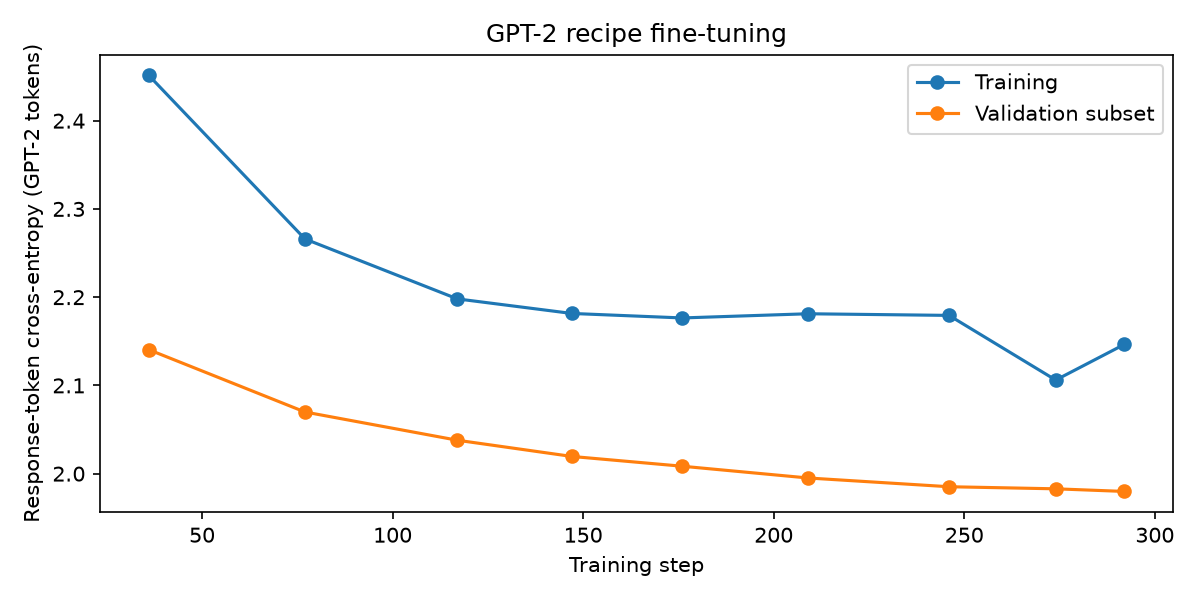

In [9]:
plot_data = pd.DataFrame(history)
plt.figure(figsize=(8, 4))
plt.plot(plot_data['step'], plot_data['train_loss'], marker='o', label='Training')
plt.plot(plot_data['step'], plot_data['validation_loss'], marker='o', label='Validation subset')
plt.xlabel('Training step')
plt.ylabel('Response-token cross-entropy (GPT-2 tokens)')
plt.title('GPT-2 recipe fine-tuning')
plt.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / 'training_loss.png', dpi=150)
plt.show()
plt.close()

## Your ingredients

Edit the list and rerun this cell. It loads the saved fine-tuned model, so no retraining is needed.

In [10]:
recipe_model = AutoModelForCausalLM.from_pretrained(BEST_DIR).to(device)
my_ingredients = ['chicken', 'garlic', 'onion', 'tomato']
my_recipe = generate_gpt2_recipe(recipe_model, my_ingredients, seed=123)
chef.print_recipe(my_recipe)

Title: onion soup
Ingredients: chicken, garlic, onion, tomato
1. preheat oven to 350 degrees.
2. cook chicken in saucepan over medium heat.
3. add garlic, onion, tomatoes, chicken, and cook, stirring, until onions are soft and fragrant.
4. add soup to pan, stirring constantly.
5. cover and simmer for 5 minutes.
6. drain soup and rinse well.
Ingredient mentions: 100% | EOS: True


## What the results mean

Pretraining gives GPT-2 general language and food knowledge that a small model trained on 9,000 recipes cannot learn on its own, so fine-tuning mainly teaches it the recipe format and how to follow the ingredient list. Ingredient mentions are still a limited score. They do not check quantities, cooking times, food safety, or whether extra ingredients were added. Inspect the drafts above before trusting any recipe.